# Lab 12: Species traits across Maine

## BIO597 Spatial Analysis of Biodiversity

Do communities differ in **what their species are like**, as well as which species
are present? Start with three prepared datasets in `../data/Lab12`:

| File | Contents |
| --- | --- |
| `ME_30KM_grid.geojson` | 30 km grid cells, richness, climate, latitude, and habitat fractions |
| `ME_Amphib_site_by_species.csv` | Occurrence counts for each species in each cell |
| `ME_traits.csv` | Five traits for species with complete trait information |

Species names have already been reconciled, occurrences assigned to cells, and
climate and habitat summarized. We can focus on four ecological questions:

1. How do typical community traits vary across space and climate?
2. How does species richness compare with functional diversity?
3. Are local species more similar in their traits than expected by chance?
4. Where do different trait combinations occur, and how do they relate to latitude, climate, and habitat?

Run from `docs/labs` using the Lab11 environment. Traits are species-level
summaries, not measurements of the particular observed animals.

## 0. Imports and choices

We combine frogs and salamanders in **30 km squares**, retaining only squares
with **at least three recorded species**. Each species receives one vote,
regardless of how many occurrence records it has. `MIN_COVERAGE` is the fraction
of a cell's species that must have complete trait information.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

CRS = "EPSG:26919"
MIN_COVERAGE = 0.8
SEED = 12

DATA = Path("../data/Lab12")
OUTPUT = Path("outputs/Lab12")
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Load the prepared communities and traits

`site_id` links each community row to a grid cell. Species names link the
community columns to the trait rows. Values in the community table are numbers
of **records**, not animal abundances; values greater than zero indicate presence.

The grid already includes three kinds of predictors:

- **Latitude:** `latitude` is the latitude of the cell midpoint, in degrees north.
- **Climate:** `bio_1` through `bio_19` are means of valid Maine raster pixels
  intersecting each square, using 1970–2000 climate normals.
- **Habitat:** six `habitat_` columns give area fractions for agriculture,
  developed land, open water, other natural habitat, upland forest, and wetland.
  They come from the 30 m Maine habitat raster and its supplied habitat lookup.

Habitat fractions sum to one across classified pixels within each cell's Maine
portion, including mapped water. NoData and unclassified pixels are excluded.
One cell (`0_1`) has no habitat-raster coverage, so its fractions are missing.
The fractions describe habitat area, not the fraction of occurrence records in each
habitat. Coastal squares contain different amounts of mapped area.

In [59]:
sites = gpd.read_file(DATA / "ME_30KM_grid.geojson")
sites = sites.set_index("site_id")
community = pd.read_csv(DATA / "ME_Amphib_site_by_species.csv", index_col="site_id")
traits = pd.read_csv(DATA / "ME_traits.csv", index_col="species")

print("Grid cells:", len(sites))
print("Recorded species:", len(community.columns))
print("Species with complete traits:", len(traits))
display(community.head())
display(traits)
display(sites.head())

Grid cells: 107
Recorded species: 16
Species with complete traits: 16


,Ambystoma maculatum,Anaxyrus americanus,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Gyrinophilus porphyriticus,Hemidactylium scutatum,Lithobates catesbeianus,Lithobates clamitans,Lithobates pipiens,Lithobates septentrionalis,Lithobates sylvaticus,Necturus maculosus,Notophthalmus viridescens,Plethodon cinereus,Pseudacris crucifer
site_id,,,,,,,,,,,,,,,,
6_8,78,20,2,40,4,0,143,93,94,158,0,116,0,47,170,76
4_7,12,32,0,17,7,1,0,8,25,3,0,18,0,4,15,12
3_6,6,16,0,12,3,0,0,34,26,2,0,25,1,5,13,22
2_3,45,42,0,39,2,0,6,71,74,0,0,65,0,15,65,57
3_4,97,104,1,42,6,0,4,51,93,0,0,147,0,39,88,94


,MaxBody,MinAgeMat,MaxClutch,MinSizeMat,MinClutch
species,,,,,
Lithobates catesbeianus,204.0,1.00,25500.0,90.0,8000.0
Lithobates clamitans,94.0,0.25,5730.0,30.0,1401.0
Lithobates sylvaticus,83.0,1.00,3000.0,31.0,300.0
Pseudacris crucifer,37.0,1.00,1500.0,22.0,200.0
Plethodon cinereus,127.0,1.00,14.0,32.0,1.0
Anaxyrus americanus,111.0,2.00,15835.0,40.0,1840.0
Dryophytes versicolor,60.0,1.00,2600.0,20.0,1000.0
Notophthalmus viridescens,140.0,0.50,375.0,51.0,200.0
Lithobates pipiens,165.0,1.00,8000.0,52.0,3045.0


,xc,yc,n_records,richness,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,...,bio_18,bio_19,latitude,habitat_agriculture,habitat_developed,habitat_open_water,habitat_other_natural,habitat_upland_forest,habitat_wetland,geometry
site_id,,,,,,,,,,,,,,,,,,,,,
6_8,515000.0,4975000.0,1184,15,6.317961,11.782170,28.852112,1024.385010,26.465834,-14.369666,...,269.083344,249.319443,44.928272,0.077493,0.127996,0.042109,0.000000,0.541349,0.211053,"POLYGON ((530000 4960000, 530000 4990000, 5000..."
4_7,455000.0,4945000.0,164,14,6.438261,12.022584,29.351254,1023.030090,26.519211,-14.439735,...,273.578949,236.144730,44.656953,0.156679,0.112265,0.012551,0.000075,0.551333,0.167097,"POLYGON ((470000 4930000, 470000 4960000, 4400..."
3_6,425000.0,4915000.0,196,13,6.660266,11.376927,28.356802,1013.331604,26.332001,-13.782974,...,271.884613,256.346161,44.384402,0.072865,0.103552,0.118122,0.000334,0.580978,0.124148,"POLYGON ((440000 4900000, 440000 4930000, 4100..."
2_3,395000.0,4825000.0,492,14,7.736003,11.132968,29.658915,941.579712,26.351988,-11.178304,...,248.657150,287.428558,43.570569,0.059894,0.424580,0.006018,0.025181,0.324895,0.159431,"POLYGON ((410000 4810000, 410000 4840000, 3800..."
3_4,425000.0,4855000.0,820,13,7.526670,9.856142,27.206020,931.669250,25.473568,-10.731306,...,251.666672,291.833344,43.844274,0.050473,0.196760,0.013384,0.025383,0.581663,0.132336,"POLYGON ((440000 4840000, 440000 4870000, 4100..."


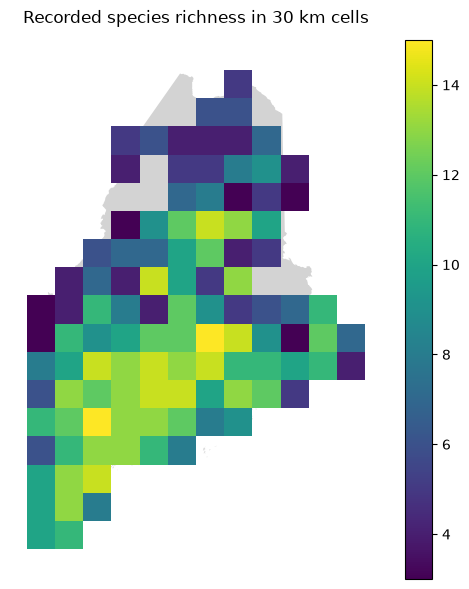

In [60]:
maine = gpd.read_file("ME_ShapeFiles/Maine_State_Boundary.shp")
maine = maine.to_crs(CRS)

ax = maine.plot(color="lightgray", figsize=(6, 7))
sites.plot(ax=ax, column="richness", legend=True, figsize=(6, 7))
ax.set_title("Recorded species richness in 30 km cells")
ax.set_axis_off()
plt.show()

The map shows sampled cells retained for analysis. Gaps do not imply amphibians
are absent. A square's richness is the number of species recorded there.

## 2. Trait coverage and a shared trait space

| Field | Interpretation | Units |
| --- | --- | --- |
| `MaxBody` | Maximum adult body length | mm |
| `MinAgeMat` | Minimum age at maturity | years |
| `MaxClutch` | Maximum clutch size | eggs/offspring per clutch |
| `MinSizeMat` | Minimum size at maturity | mm |
| `MinClutch` | Minimum clutch size | eggs/offspring per clutch |

The prepared trait table contains only complete profiles. Three recorded species
are excluded: **Ambystoma laterale** lacks clutch-size information;
**Lithobates palustris** lacks maturity age and size; and
**Osteopilus septentrionalis** has no matching row in the supplied trait source.
They still contribute to recorded species richness. Missing traits are not zeros.

For this lab, every trait analysis uses the same complete species pool. A cell's
trait coverage is the proportion of its recorded species in that pool.

,PC1,PC2
MaxBody,0.438426,0.458840
MinAgeMat,0.475350,0.062643
MaxClutch,-0.467545,0.468661
MinSizeMat,0.425935,0.518164
MinClutch,-0.426386,0.545348


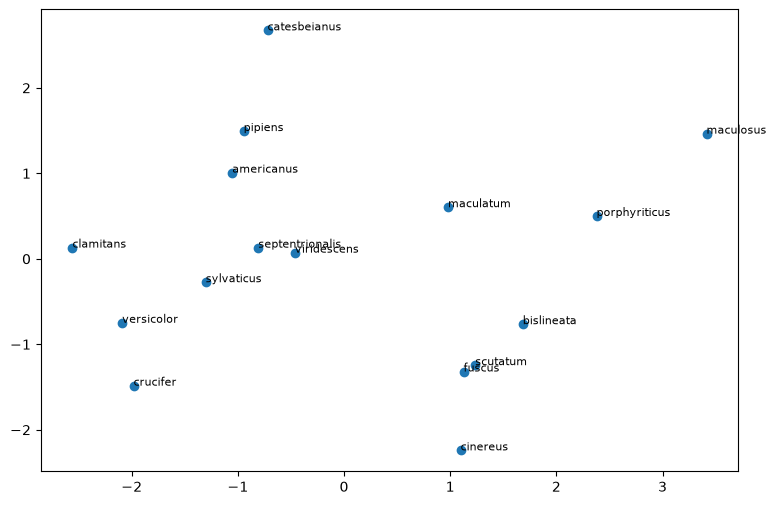

In [61]:

TRAIT_COLUMNS = list(traits.columns)
TRAIT_LABELS = {"MaxBody": "Maximum adult length (mm)",
                "MinAgeMat": "Minimum maturity age (years)",
                "MaxClutch": "Maximum clutch size",
                "MinSizeMat": "Minimum size at maturity (mm)",
                "MinClutch": "Minimum clutch size"}
trait_lookup = traits

# Log and standardize the data
logged = np.log10(traits)
scaler = StandardScaler()
standardized = scaler.fit_transform(logged)
trait_space = pd.DataFrame(standardized, index=traits.index, columns=TRAIT_COLUMNS)

# Perform PCA
trait_pca = PCA(n_components=2)
scores = trait_pca.fit_transform(standardized)
species_scores = pd.DataFrame(scores, index=traits.index, columns=["PC1", "PC2"])

# Scatterplot of PCs
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(species_scores["PC1"], species_scores["PC2"])
for name, point in species_scores.iterrows():
    epithet = name.split()[1]
    ax.text(point["PC1"], point["PC2"], epithet, fontsize=8)

loadings = pd.DataFrame(trait_pca.components_.T, index=TRAIT_COLUMNS, columns=["PC1", "PC2"])
display(loadings)

We log-transform traits so a change from 1 to 2 years is comparable to a change
from 2 to 4. Standardization keeps large numerical clutch sizes from dominating
length and maturity age. This PCA summarizes **species traits**, rather than
Lab11's GDM-transformed climate predictors.

**Discuss:** Could excluding species with incomplete traits change a cell's
apparent trait composition? Why retain them when counting richness?

## Step 1. Map the typical traits of recorded communities

For each trait, average the **log values across recorded species**, then return
the result to the original units: a geometric mean. For `MaxBody`, this means
"typical species' maximum adult length," not mean size of animals in the cell.
Use species in the prepared trait table. Mask the mean when fewer than
`MIN_COVERAGE` of a cell's recorded species have complete trait profiles.
Keep the coverage beside the mean.

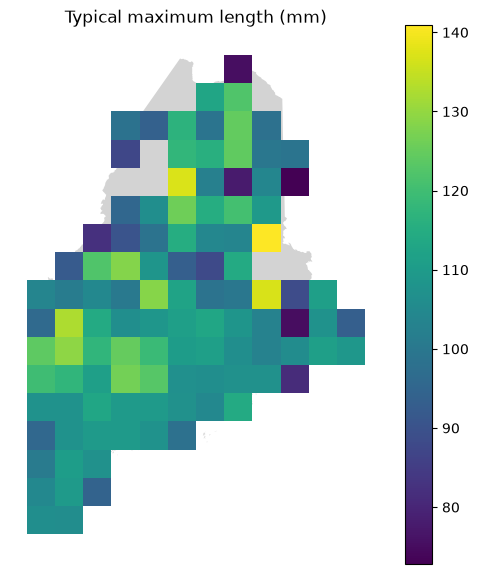

In [62]:
def summarize_trait(sites, community, column):
    result = sites.copy()
    means = []
    coverages = []
    for site_id, row in community.iterrows():
        # Get only the species that occur in this community
        names = row[row > 0].index
        # reindex the trait lookup table to only have those species present
        species_traits = trait_lookup.reindex(names)
        values = species_traits[column]
        values = values.dropna()
        # calculate the fraction of species that have trait info
        coverage = len(values) / len(names)
        coverages.append(coverage)
        if coverage >= MIN_COVERAGE:
            log_values = np.log10(values)
            means.append(10 ** log_values.mean())
        else:
            means.append(np.nan)
    result["trait_mean"] = means
    result["trait_coverage"] = coverages
    return result


trait_maps = {}
for column in TRAIT_COLUMNS:
    trait_maps[column] = summarize_trait(sites, community, column)

ax = maine.plot(color="lightgray", figsize=(6, 7))
sites.plot(ax=ax, color="lightgray", figsize=(6, 7))
trait_maps["MaxBody"].plot(ax=ax, column="trait_mean", legend=True)
ax.set_title("Typical maximum length (mm)")
ax.set_axis_off()
plt.show()

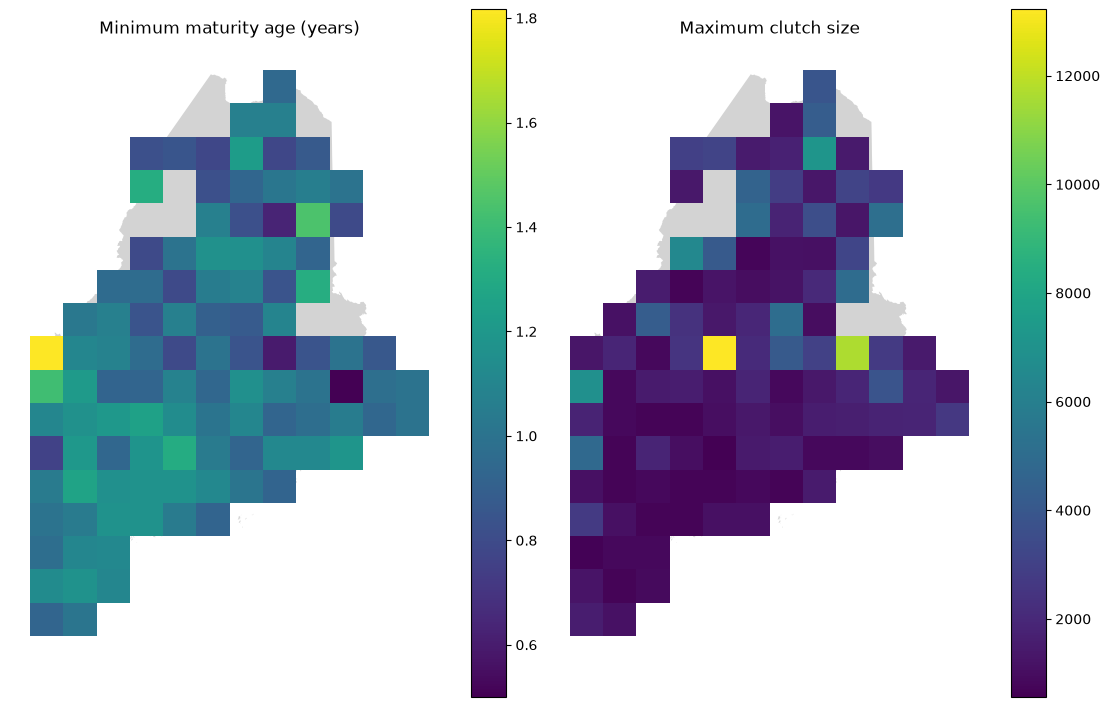

In [63]:
# Map maturity and reproduction traits in the same way.
fig, axes = plt.subplots(1, 2, figsize=(11, 7), layout="constrained")
for ax, column in zip(axes, ["MinAgeMat", "MaxClutch"]):
    maine.plot(ax=ax, color="lightgray", figsize=(6, 7))
    sites.plot(ax=ax, color="lightgray")
    trait_maps[column].plot(ax=ax, column="trait_mean", legend=True)
    ax.set_title(TRAIT_LABELS[column])
    ax.set_axis_off()
plt.show()

{'latitude': np.float64(-0.07),
 'bio_1': np.float64(0.04),
 'bio_2': np.float64(0.21),
 'bio_3': np.float64(0.15),
 'bio_4': np.float64(0.0),
 'bio_5': np.float64(0.17),
 'bio_6': np.float64(0.0),
 'bio_7': np.float64(0.03),
 'bio_8': np.float64(-0.01),
 'bio_9': np.float64(-0.1),
 'bio_10': np.float64(0.11),
 'bio_11': np.float64(0.02),
 'bio_12': np.float64(-0.11),
 'bio_13': np.float64(-0.16),
 'bio_14': np.float64(-0.08),
 'bio_15': np.float64(-0.2),
 'bio_16': np.float64(-0.2),
 'bio_17': np.float64(-0.02),
 'bio_18': np.float64(0.03),
 'bio_19': np.float64(-0.11),
 'habitat_agriculture': np.float64(0.09),
 'habitat_developed': np.float64(0.04),
 'habitat_open_water': np.float64(0.14),
 'habitat_other_natural': np.float64(0.15),
 'habitat_upland_forest': np.float64(0.1),
 'habitat_wetland': np.float64(-0.19)}

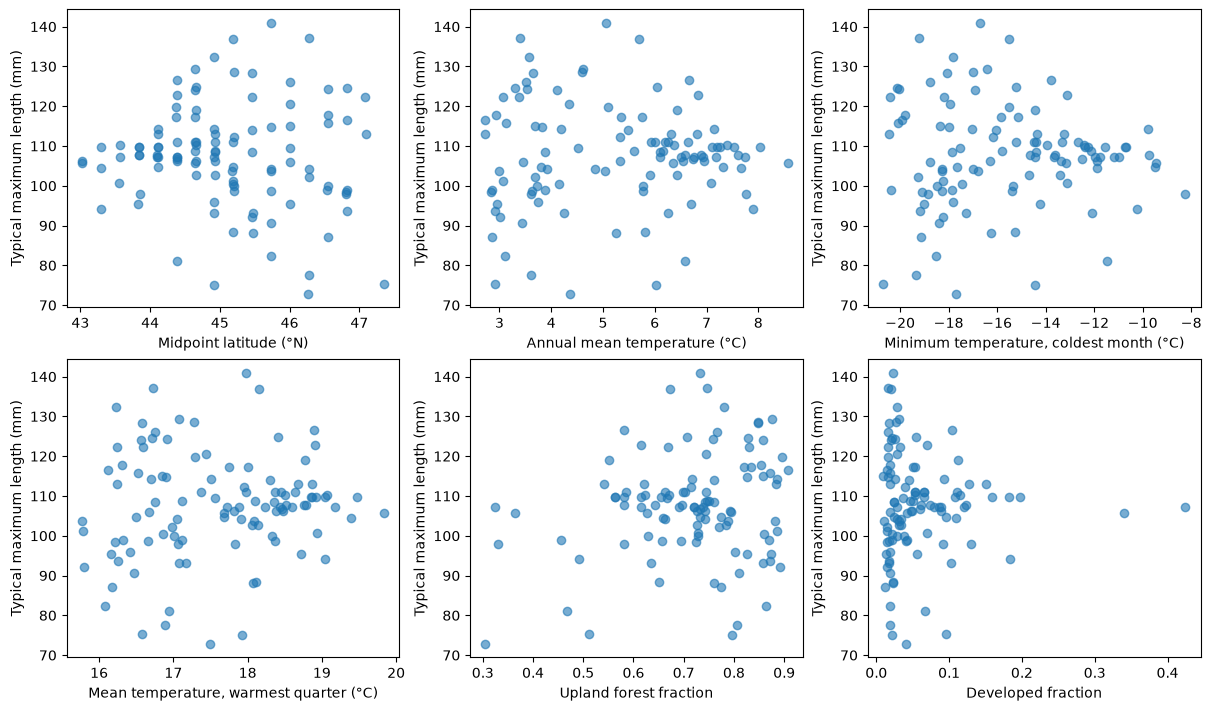

In [76]:
CLIMATE_COLUMNS = {
    "bio_1": "Annual mean temperature (°C)",
    "bio_2": "Mean diurnal temperature range (°C)",
    "bio_3": "Isothermality (%)",
    "bio_4": "Temperature seasonality (SD × 100)",
    "bio_5": "Maximum temperature, warmest month (°C)",
    "bio_6": "Minimum temperature, coldest month (°C)",
    "bio_7": "Annual temperature range (°C)",
    "bio_8": "Mean temperature, wettest quarter (°C)",
    "bio_9": "Mean temperature, driest quarter (°C)",
    "bio_10": "Mean temperature, warmest quarter (°C)",
    "bio_11": "Mean temperature, coldest quarter (°C)",
    "bio_12": "Annual precipitation (mm)",
    "bio_13": "Precipitation, wettest month (mm)",
    "bio_14": "Precipitation, driest month (mm)",
    "bio_15": "Precipitation seasonality (CV)",
    "bio_16": "Precipitation, wettest quarter (mm)",
    "bio_17": "Precipitation, driest quarter (mm)",
    "bio_18": "Precipitation, warmest quarter (mm)",
    "bio_19": "Precipitation, coldest quarter (mm)",
}

HABITAT_COLUMNS = {
    "habitat_agriculture": "Agriculture fraction",
    "habitat_developed": "Developed fraction",
    "habitat_open_water": "Open water fraction",
    "habitat_other_natural": "Other natural habitat fraction",
    "habitat_upland_forest": "Upland forest fraction",
    "habitat_wetland": "Wetland fraction",
}
PREDICTORS = {"latitude": "Midpoint latitude (°N)"}
PREDICTORS.update(CLIMATE_COLUMNS)
PREDICTORS.update(HABITAT_COLUMNS)

table = trait_maps["MaxBody"]
corrs = {}
for predictor in PREDICTORS:
    data = table.dropna(subset=["trait_mean", predictor])
    rho = data[predictor].corr(data["trait_mean"], method="spearman")
    corrs[predictor] = round(rho, 2)
display(corrs)

# Show examples from latitude, climate, and habitat.
PLOT_PREDICTORS = ["latitude", "bio_1", "bio_6", "bio_10",
                   "habitat_upland_forest", "habitat_developed"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, predictor in zip(axes.flat, PLOT_PREDICTORS):
    data = table.dropna(subset=["trait_mean", predictor])
    ax.scatter(data[predictor], data["trait_mean"], alpha=0.6)
    ax.set(xlabel=PREDICTORS[predictor], ylabel="Typical maximum length (mm)")
plt.show()

**Discuss:** Where do typical trait values change? Could one commonly present
species, uneven reporting or missing traits explain part of the map? These are
patterns in species composition, not evidence that individual animals change
size across Maine. Nearby cells share species and environmental conditions,
so the correlations are descriptive.

## Step 2. Compare species richness with functional diversity

Use species with all five traits so every distance refers to the same
dimensions. Keep functional summaries for cells with **at least three
trait-covered species** and at least 80% trait coverage.

**Functional dispersion (FDis)** is the mean distance of a cell's species to
their centroid in trait space. Calculate it using all five standardized traits;
the two-dimensional PCA is only a picture of that space. High FDis means a wider
spread of the measured traits.

In [65]:
def dispersion(values):
    centroid = values.mean(axis=0)
    squared_differences = (values - centroid) ** 2
    distances = np.sqrt(squared_differences.sum(axis=1))
    return distances.mean()

values = []
for site_id, row in community.iterrows():
    names = row[row > 0].index
    species_traits = trait_space.loc[names]
    values.append(dispersion(species_traits.to_numpy()))
sites["functional_dispersion"] = values


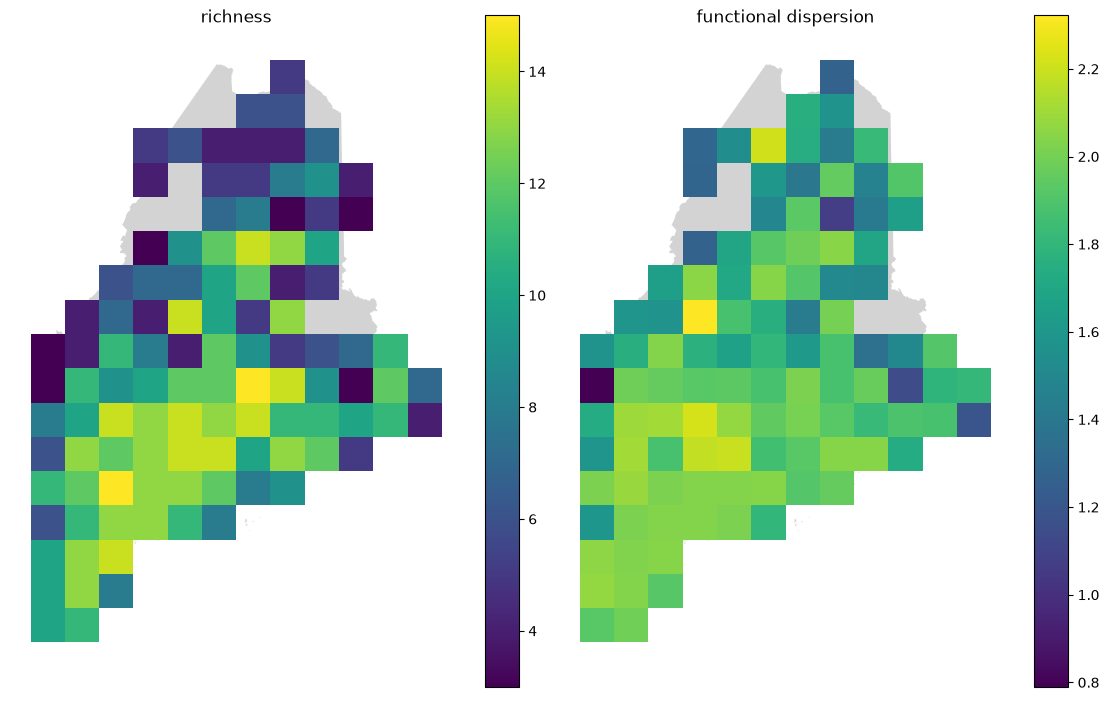

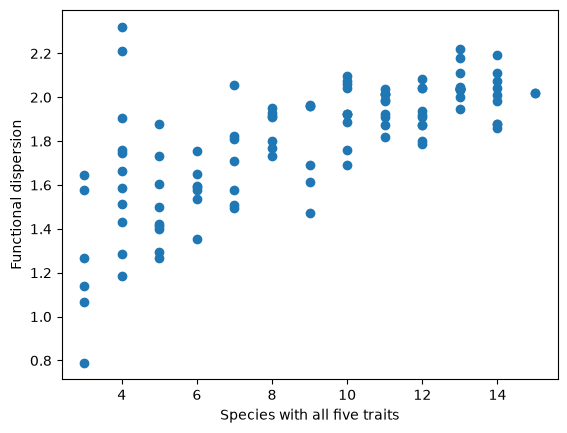

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(11, 7), layout="constrained")
for ax, column in zip(axes, ["richness", "functional_dispersion"]):
    maine.plot(ax=ax, color="lightgray", figsize=(6, 7))
    sites.plot(ax=ax, color="lightgray")
    sites.plot(ax=ax, column=column, legend=True)
    ax.set_title(column.replace("_", " "))
    ax.set_axis_off()
plt.show()

plt.scatter(sites["richness"], sites["functional_dispersion"])
plt.xlabel("Species with all five traits")
plt.ylabel("Functional dispersion")
plt.show()

### Hold richness fixed and look at the species

Compare two cells that each have **three trait-covered species**, but low versus
high FDis. Colored points are the local species; gray points are the regional
pool. The star is the centroid. FDis uses all five traits, while this PCA picture
shows only two axes.

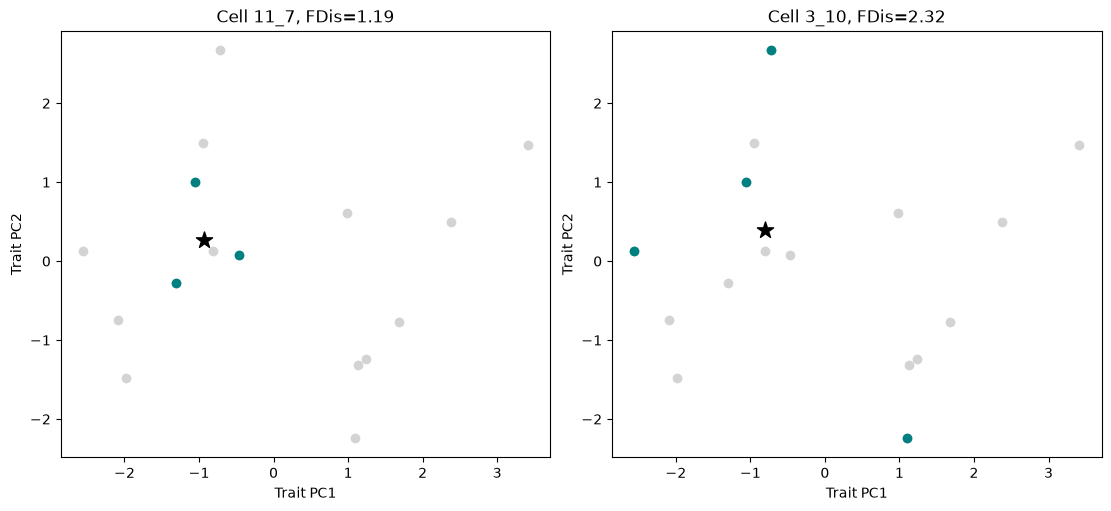

In [10]:
candidates = sites[sites["richness"] == 4]
lowest = candidates["functional_dispersion"].idxmin()
highest = candidates["functional_dispersion"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, site_id in zip(axes, [lowest, highest]):
    present = community.loc[site_id]
    names = present[present > 0].index
    selected = species_scores.loc[names]
    ax.scatter(species_scores["PC1"], species_scores["PC2"], color="lightgray")
    ax.scatter(selected["PC1"], selected["PC2"], color="teal")
    ax.scatter(selected["PC1"].mean(), selected["PC2"].mean(), marker="*", color="black", s=150)
    fdis = sites.loc[site_id, "functional_dispersion"]
    ax.set(title=f"Cell {site_id}, FDis={fdis:.2f}", xlabel="Trait PC1", ylabel="Trait PC2")
plt.show()

**Discuss:** Can communities have the same richness but different trait spread?
Which species create the contrast in the examples? Could a missing species have
changed the centroid or spread? Try a stricter coverage requirement. FDis is not
simply a species count; nevertheless, a richness-preserving null model below
provides a useful comparison for this particular regional pool.

## Step 3. Are traits more clustered than expected?

Keep the observed community matrix fixed and **shuffle complete trait rows
among species**. Each cell keeps its species richness, and the five traits
travel together so their correlations are preserved.

The regional pool contains the 16 species in the prepared trait table, including both frogs and salamanders. We ask whether local communities
have more or less trait variation than expected from this pool.

In [67]:
def null_dispersion(presence, trait_space, n_random):
    # Match the species order, then turn occurrence counts into presence/absence.
    presence = presence[trait_space.index]
    presence = presence > 0
    values = trait_space.to_numpy()
    rng = np.random.default_rng(SEED)

    # Store one dispersion value per randomization and grid cell.
    simulated = np.zeros((n_random, len(presence)))
    for draw in range(n_random):
        # Reassign whole trait profiles among species; keep all five traits together.
        shuffled = rng.permutation(values)
        for site_number, present in enumerate(presence.to_numpy()):
            # Keep the cell's species list fixed and calculate its shuffled dispersion.
            simulated[draw, site_number] = dispersion(shuffled[present])
    return simulated

N_RANDOM = 1000
null_sites = sites.copy()
null_draws = null_dispersion(community, trait_space, N_RANDOM)

# Summarize the dispersion expected by chance for each cell.
null_sites["null_mean"] = null_draws.mean(axis=0)
null_sites["null_sd"] = null_draws.std(axis=0, ddof=1)

# Compare observed dispersion with the null mean, in units of null SD.
# Leave the effect size missing if the randomizations have no variation.
null_sites.loc[null_sites["null_sd"] < 1e-10, "null_sd"] = np.nan
difference = null_sites["functional_dispersion"] - null_sites["null_mean"]
null_sites["ses_fdis"] = difference / null_sites["null_sd"]

The **standardized effect size** is `(observed FDis - null mean) / null SD`.
Negative values indicate clustering; positive values indicate greater spread
than expected. A cell containing the entire regional pool has the same FDis
after every shuffle, so its effect size is undefined and left missing.

Clustering is consistent with environmental filtering, but it does not establish
filtering as the cause. The regional pool, shared ancestry and observation
process can also affect the pattern.

The maps use a shared color scale from −3 to +3 SD; values beyond these limits
use the end colors.

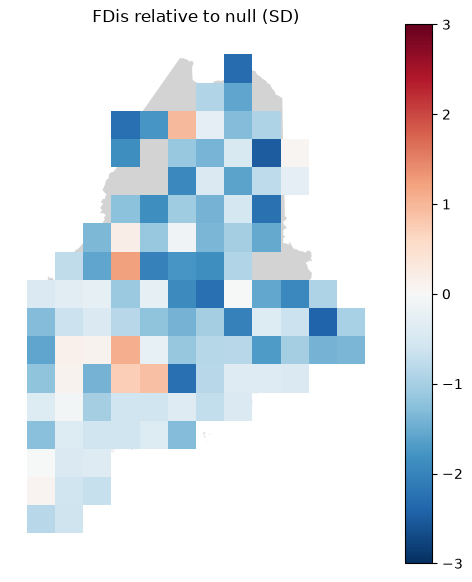

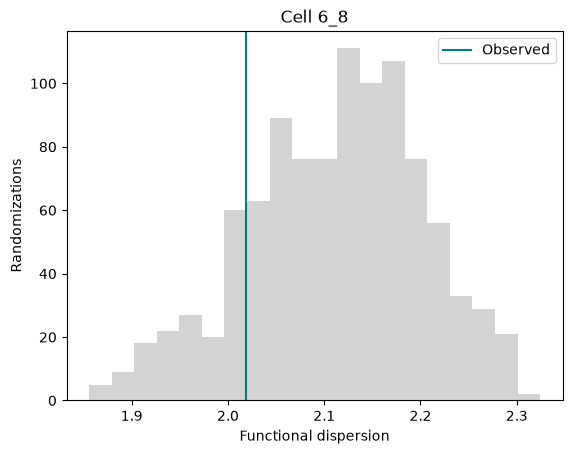

In [68]:
ax = maine.plot(color="lightgray", figsize=(6, 7))
sites.plot(ax=ax, color="lightgray", figsize=(6, 7))
null_sites.plot(ax=ax, column="ses_fdis", cmap="RdBu_r", vmin=-3, vmax=3, legend=True)
ax.set_title("FDis relative to null (SD)")
ax.set_axis_off()
plt.show()

# Look at the randomization distribution for one cell.
examples = null_sites.dropna(subset=["ses_fdis"])
site_id = examples.index[0]
position = null_sites.index.get_loc(site_id)
plt.hist(null_draws[:, position], bins=20, color="lightgray")
observed = null_sites.loc[site_id, "functional_dispersion"]
plt.axvline(observed, color="teal", label="Observed")
plt.title(f"Cell {site_id}")
plt.xlabel("Functional dispersion")
plt.ylabel("Randomizations")
plt.legend()
plt.show()

In [ ]:
## Step 4. Evaluate correlations between FDis and environmental predictors


Pearson correlations


{'latitude': np.float64(-0.46),
 'bio_1': np.float64(0.45),
 'bio_2': np.float64(-0.09),
 'bio_3': np.float64(0.3),
 'bio_4': np.float64(-0.36),
 'bio_5': np.float64(0.38),
 'bio_6': np.float64(0.41),
 'bio_7': np.float64(-0.31),
 'bio_8': np.float64(-0.31),
 'bio_9': np.float64(0.25),
 'bio_10': np.float64(0.46),
 'bio_11': np.float64(0.43),
 'bio_12': np.float64(0.22),
 'bio_13': np.float64(0.14),
 'bio_14': np.float64(0.3),
 'bio_15': np.float64(-0.37),
 'bio_16': np.float64(0.06),
 'bio_17': np.float64(0.34),
 'bio_18': np.float64(-0.33),
 'bio_19': np.float64(0.22),
 'habitat_agriculture': np.float64(0.08),
 'habitat_developed': np.float64(0.36),
 'habitat_open_water': np.float64(-0.03),
 'habitat_other_natural': np.float64(0.1),
 'habitat_upland_forest': np.float64(-0.21),
 'habitat_wetland': np.float64(-0.03)}

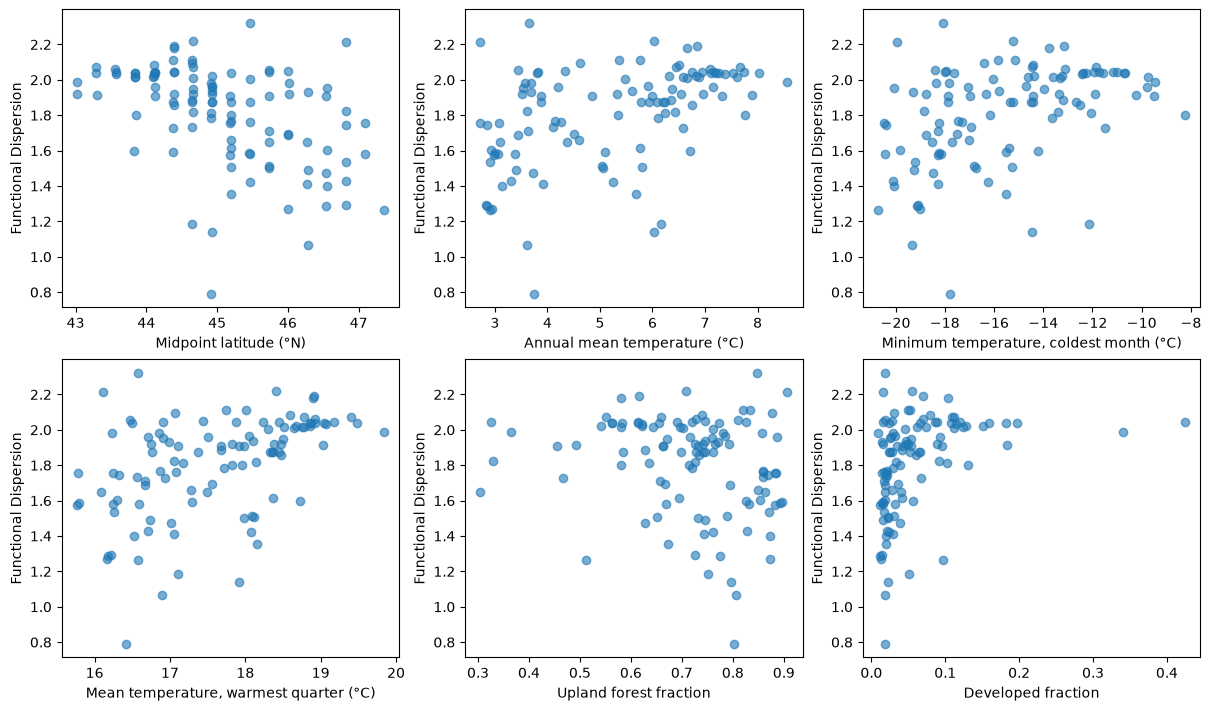

In [77]:
Fdis_corrs = {}
for predictor in PREDICTORS:
    data = null_sites.dropna(subset=["functional_dispersion", predictor])
    r = data[predictor].corr(data["functional_dispersion"], method="pearson")
    Fdis_corrs[predictor] = round(r, 2)
print("Pearson correlations")
display(Fdis_corrs)

fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, predictor in zip(axes.flat, PLOT_PREDICTORS):
    data = null_sites.dropna(subset=["functional_dispersion", predictor])
    ax.scatter(data[predictor], data["functional_dispersion"], alpha=0.6)
    ax.set(xlabel=PREDICTORS[predictor], ylabel="Functional Dispersion")
plt.show()

**Discuss:** Which cells are clustered or dispersed relative to this regional
pool? Do relationships with latitude, climate, or habitat suggest a useful
hypothesis about filtering? Could regional availability, shared ancestry or
incomplete species lists produce the same pattern? Our joint shuffles preserve
species incidence, not the association between traits and geographic occurrence.
Changing the pool or randomization would ask a different question.

These correlations are descriptive. Latitude, climate, and habitat are related,
so a strong correlation does not identify a unique cause. Habitat fractions also
sum to one: more of one habitat means less of at least one other habitat.

## Step 5. Put the trait–environment relationships on the map

Summarize the **five community mean traits** in a new PCA. Each row is now a
30 km cell, rather than a species. Reuse the geometric means from Step 1,
log-transform them, and standardize each trait before the PCA.

Make two linked panels:

- **A:** Grid cells colored by their positions on the first two community trait PCs.
- **B:** The same cells and colors in PCA space, with latitude, climate, and habitat arrows.

Similar colors indicate similar positions on these two axes. They summarize
**typical trait combinations**, not richness or the amount of variation within a
cell. Communities with similar means can still have different FDis.

Rank all predictors by their average squared correlation with the five log
community mean traits. Show arrows for latitude, the leading climate variable,
and the leading habitat fraction. This is a descriptive ranking across all five
traits, not a significance test. The arrows show correlations with the two
displayed PCs; they do not represent causal effects.

In [74]:
from sklearn.preprocessing import MinMaxScaler

# Reuse the community mean traits already calculated in Step 1.
community_traits = pd.DataFrame(index=sites.index)
for trait in TRAIT_COLUMNS:
    community_traits[trait] = np.log10(trait_maps[trait]["trait_mean"])
community_traits = community_traits.dropna()

# Give each trait equal weight, then summarize differences among cells.
scaler = StandardScaler()
scaled_traits = scaler.fit_transform(community_traits)
community_pca = PCA(n_components=2)
scores = community_pca.fit_transform(scaled_traits)
community_scores = pd.DataFrame(scores, index=community_traits.index, columns=["PC1", "PC2"])
community_loadings = pd.DataFrame(community_pca.components_.T,
                                 index=TRAIT_COLUMNS, columns=["PC1", "PC2"])
display(community_loadings)

# Compare latitude, climate, and habitat using all five community mean traits.
predictor_strength = {}
for predictor in PREDICTORS:
    squared_correlations = []
    for trait in TRAIT_COLUMNS:
        r = sites[predictor].corr(community_traits[trait])
        squared_correlations.append(r ** 2)
    predictor_strength[predictor] = np.mean(squared_correlations)

predictor_ranking = pd.Series(predictor_strength, name="mean_r_squared")
predictor_ranking = predictor_ranking.sort_values(ascending=False)
best_climate = predictor_ranking.loc[list(CLIMATE_COLUMNS)].idxmax()
best_habitat = predictor_ranking.loc[list(HABITAT_COLUMNS)].idxmax()
FOCUS = ["latitude", best_climate, best_habitat]
display(predictor_ranking.head())

# Use the same PCA-based colors in the map and the scatterplot.
color_scores = MinMaxScaler().fit_transform(community_scores)
community_colors = np.zeros((len(community_scores), 3))
community_colors[:, :2] = color_scores
community_colors[:, 2] = 0.5
map_sites = sites.loc[community_scores.index].copy()
map_sites[["PC1", "PC2"]] = community_scores

,PC1,PC2
MaxBody,-0.281890,0.613426
MinAgeMat,-0.505515,0.046720
MaxClutch,0.557972,0.290026
MinSizeMat,-0.243072,0.643070
MinClutch,0.542748,0.351954


latitude    0.107551
bio_6       0.094512
bio_11      0.090707
bio_4       0.088213
bio_7       0.088138
Name: mean_r_squared, dtype: float64

Midpoint latitude (°N) Midpoint latitude (°N)
BIO6 Minimum temperature, coldest month (°C)
Developed fraction Developed fraction


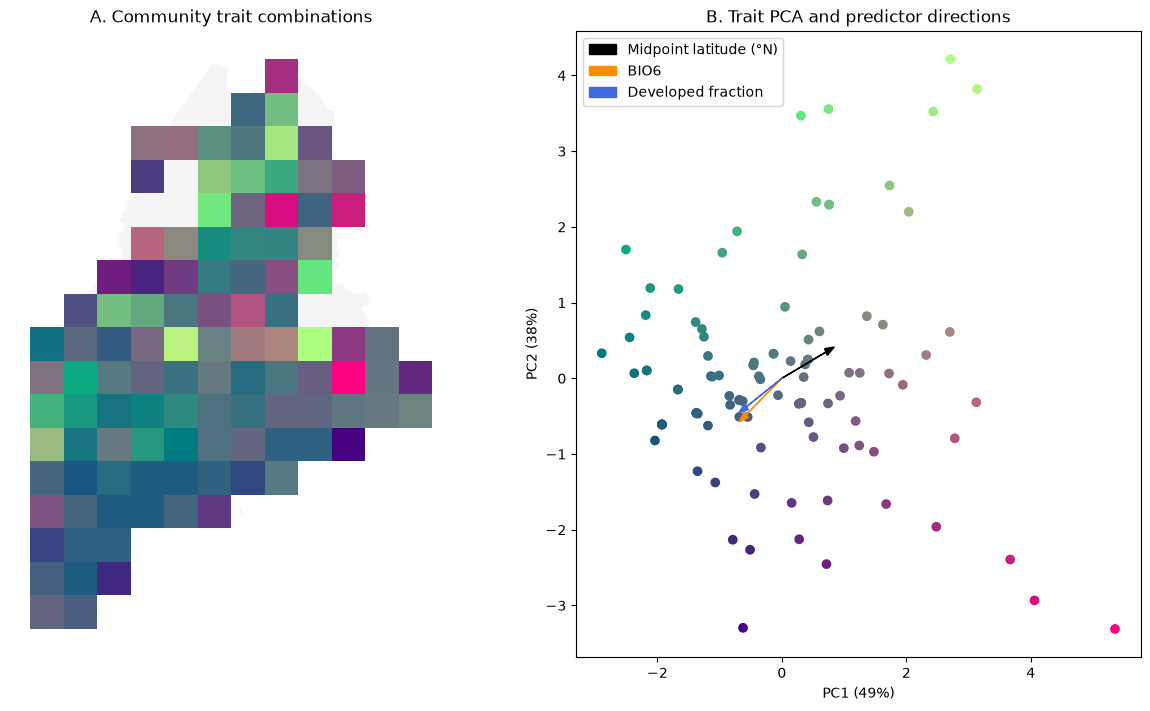

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7), layout="constrained")

# A. Show where the observed community trait combinations occur.
maine.plot(ax=axes[0], color="whitesmoke")
sites.plot(ax=axes[0], color="lightgray")
map_sites.plot(ax=axes[0], color=community_colors)
axes[0].set_title("A. Community trait combinations")
axes[0].set_axis_off()

# B. Use PCA space as the color key and add latitude, climate, and habitat directions.
ax = axes[1]
ax.scatter(community_scores["PC1"], community_scores["PC2"], c=community_colors)
for predictor, color in zip(FOCUS, ["black", "darkorange", "royalblue"]):
    # Scale both correlations equally so the arrows are easy to see.
    x = 2 * sites[predictor].corr(community_scores["PC1"])
    y = 2 * sites[predictor].corr(community_scores["PC2"])
    label = PREDICTORS[predictor]
    if predictor in CLIMATE_COLUMNS:
        label = "BIO" + predictor.split("_")[1]
    ax.arrow(0, 0, x, y, head_width=0.1, length_includes_head=True,
             color=color, label=label)
    print(label, PREDICTORS[predictor])
ax.legend()
ax.set(title="B. Trait PCA and predictor directions",
       xlabel=f"PC1 ({community_pca.explained_variance_ratio_[0]:.0%})",
       ylabel=f"PC2 ({community_pca.explained_variance_ratio_[1]:.0%})")

figure_path = OUTPUT / "community_trait_environment_map.png"
fig.savefig(figure_path, dpi=200)
plt.show()

**Interpret:** Use the loadings to describe the trait combinations at each end
of PC1 and PC2. Where do those combinations occur in Maine? In what direction
does each predictor increase in the PCA plot? How much trait variation
is retained by these two axes?

Compare this map with the FDis map: do communities with similar typical traits
also have similar trait spread? The colors describe observed community means,
not a fitted prediction surface. Predictor rankings are exploratory, and nearby
cells share species and environmental conditions.

## Interpretation and deliverables

Submit the completed notebook and a **400–600 word synthesis** supported by at
least three figures. Address:

1. Geographic, climatic, and habitat patterns in typical traits, without treating
   species summaries as measurements of local animals.
2. How richness and trait dispersion differ, including an equal-richness example.
3. What the null model says about clustering and what it cannot establish.
4. What the community trait PCA map adds, including its predictor arrows
   and the distinction between typical traits and trait spread.
5. Which species are missing from the prepared trait table and how
   site-level coverage and uneven sampling affect the interpretation.

Do not describe raw record frequency as animal abundance or a trait-data gap as
an ecological absence.

### Sources

- [AmphiTraits: USGS data release](https://doi.org/10.5066/P135WFOE).
- [AmphiBIO measurement definitions](https://pmc.ncbi.nlm.nih.gov/articles/PMC5584397/)
  for trait measurement definitions.
- [Amphibian Species of the World: Lithobates](https://amphibiansoftheworld.amnh.org/Amphibia/Anura/Ranidae/Lithobates),
  [bullfrog](https://amphibiansoftheworld.amnh.org/Amphibia/Anura/Ranidae/Lithobates/Lithobates-catesbeianus),
  [green frog](https://amphibiansoftheworld.amnh.org/Amphibia/Anura/Ranidae/Lithobates/Lithobates-clamitans),
  [mink frog](https://amphibiansoftheworld.amnh.org/Amphibia/Anura/Ranidae/Lithobates/Lithobates-septentrionalis),
  [wood frog](https://amphibiansoftheworld.amnh.org/Amphibia/Anura/Ranidae/Lithobates/Lithobates-sylvaticus)
  and [northern leopard frog](https://amphibiansoftheworld.amnh.org/Amphibia/Anura/Ranidae/Lithobates/Lithobates-pipiens)
  for the explicit crosswalk.
- [Laliberté & Legendre (2010)](https://doi.org/10.1890/08-2244.1), functional dispersion.